  # 0. Préparation de l'environnement

In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.13.0+cpu
Device : cpu


1. Jeu de données MNIST

MNIST contient 60 000 images d'entraînement et 10 000 images de test de chiffres manuscrits. Chaque image est en niveaux de gris et mesure 28 x 28 pixels.

In [28]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


Batch d'images : torch.Size([128, 1, 28, 28])
Batch de labels : torch.Size([128])
Valeurs des pixels : 0.0 -> 1.0


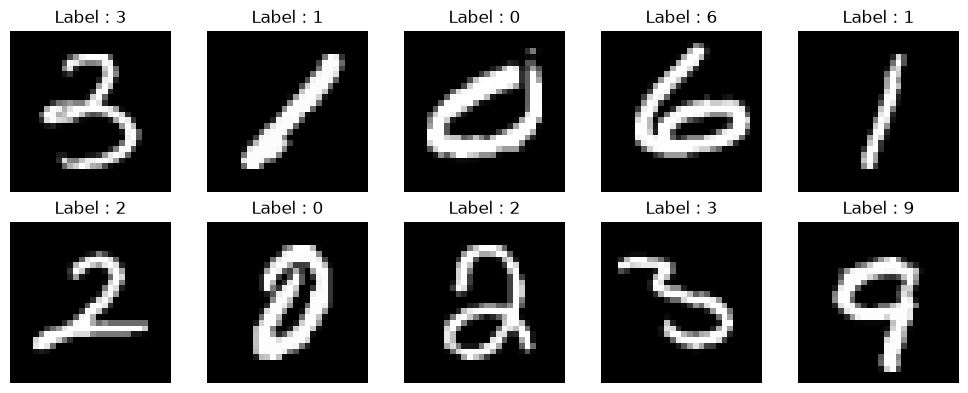

In [29]:
images, labels = next(iter(train_loader))
print("Batch d'images :", images.shape)
print("Batch de labels :", labels.shape)
print("Valeurs des pixels :", float(images.min()), "->", float(images.max()))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for image, label, ax in zip(images[:10], labels[:10], axes.flat):
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(f"Label : {label.item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [30]:
# Cette cellule servira pour la Partie I : classification.

# Partie I - Modele discriminatif

## 2. Classification : apprendre P(y|x)

Le classifieur recoit une image `x` et predit le chiffre `y`. Il apprend a distinguer les classes 0 a 9, mais il ne genere pas de nouvelles images.

### Etape 1 - Construire le classifieur

`Flatten` transforme chaque image `[1, 28, 28]` en un vecteur de `784` pixels. Les couches `Linear` apprennent ensuite des caracteristiques et produisent 10 scores, un par chiffre.

In [31]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


classifier = Classifier().to(device)
print(classifier)

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


### Verification des formes

Cette verification confirme que le modele transforme un lot `[B, 1, 28, 28]` en 10 scores `[B, 10]`.

In [32]:
with torch.no_grad():
    sample_logits = classifier(images[:4].to(device))

print("Entree :", images[:4].shape)
print("Sortie :", sample_logits.shape)
print("Classe predite pour le premier exemple :", sample_logits[0].argmax().item())

Entree : torch.Size([4, 1, 28, 28])
Sortie : torch.Size([4, 10])
Classe predite pour le premier exemple : 6


### Etape 2 - Definir la fonction de perte et l'optimiseur

`CrossEntropyLoss` compare les 10 scores du modele au label correct. `Adam` modifie les poids du reseau pour reduire cette erreur.

In [33]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

### Etape 3 - Entrainement

A chaque lot, le modele predit, calcule l'erreur, puis `backward()` calcule les gradients. `optimizer.step()` applique la mise a jour des poids.

In [34]:
def train_classifier(model, loader, criterion, optimizer, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0.0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        mean_loss = total_loss / len(loader)
        print(f"Epoch {epoch + 1}/{epochs} - Loss = {mean_loss:.4f}")


train_classifier(classifier, train_loader, criterion, optimizer, epochs=3)

Epoch 1/3 - Loss = 0.4220
Epoch 2/3 - Loss = 0.1939
Epoch 3/3 - Loss = 0.1387


### Etape 4 - Evaluer le modele

On desactive l'apprentissage avec `eval()` et on ne calcule pas de gradients. L'accuracy mesure la proportion d'images correctement classees.

In [35]:
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        predictions = model(x).argmax(dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

    return correct / total


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy sur le jeu de test = {100 * accuracy:.2f}%")

Accuracy sur le jeu de test = 96.22%


### Conclusion

Le reseau apprend la relation `x -> y` : il reconnait le chiffre present dans une image. C'est un modele **discriminatif**, car il separe les classes. Il ne sait pas produire une nouvelle image de chiffre ; cette generation sera abordee avec les modeles generatifs.

In [36]:
# Partie II : Autoencodeur
# Cette cellule est un emplacement reserve pour la Partie II.

# Partie II - Autoencodeur

Un autoencodeur apprend a reconstruire son entree : `x -> encodeur -> z -> decodeur -> x_hat`. Les labels ne sont pas necessaires, car l'image originale sert de cible.

### Etape 1 - Construire le modele

L'encodeur compresse 784 pixels en 2 nombres. Le decodeur transforme ces 2 nombres en une image 28 x 28. La dimension latente 2 permet aussi de dessiner les representations.

In [37]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.ReLU(),
            nn.Linear(32, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))


ae = Autoencoder(latent_dim=2).to(device)
print(ae)

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### Etape 2 - Perte de reconstruction

`MSELoss` compare chaque pixel de l'image originale et de l'image reconstruite. Une loss faible signifie que les deux images sont proches.

In [38]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)

def train_autoencoder(model, loader, epochs=5):
    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        for x, _ in loader:
            x = x.to(device)
            reconstruction = model(x)
            loss = ae_criterion(reconstruction, x)
            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch + 1}/{epochs} - Loss = {total_loss / len(loader):.4f}")

train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0666
Epoch 2/5 - Loss = 0.0533
Epoch 3/5 - Loss = 0.0502
Epoch 4/5 - Loss = 0.0475
Epoch 5/5 - Loss = 0.0456


### Etape 3 - Reconstruire les images

La premiere ligne montre les images originales et la deuxieme leurs reconstructions. Cette comparaison verifie visuellement l'apprentissage.

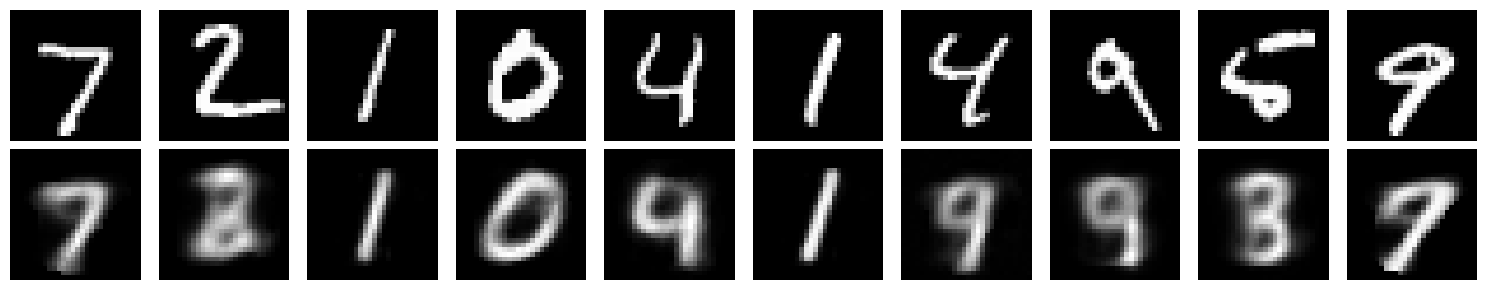

In [39]:
ae.eval()
images_test, labels_test = next(iter(test_loader))
with torch.no_grad():
    reconstructions = ae(images_test[:10].to(device)).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(images_test[i, 0], cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i, 0], cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Originale")
axes[1, 0].set_ylabel("Reconstruite")
plt.tight_layout()
plt.show()

### Etape 4 - Visualiser l'espace latent

Chaque image devient un point `(z1, z2)`. Les couleurs indiquent les labels uniquement pour lire le graphique ; ils n'ont pas servi a entrainer l'autoencodeur.

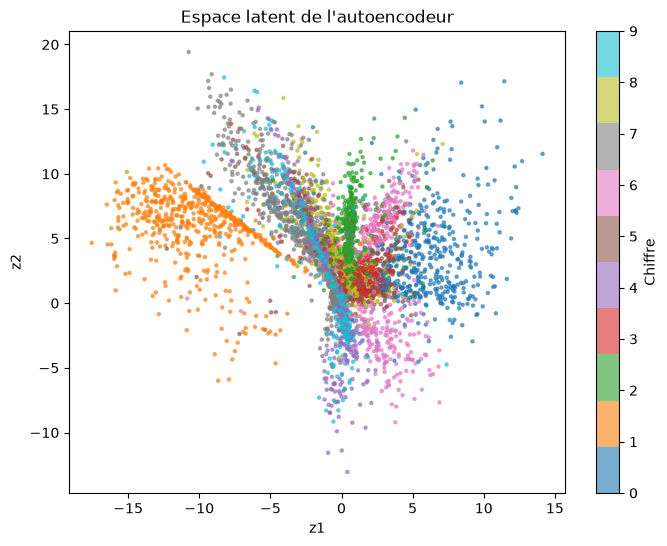

In [40]:
latent_points, latent_labels = [], []
ae.eval()
with torch.no_grad():
    for x, y in test_loader:
        latent_points.append(ae.encode(x.to(device)).cpu())
        latent_labels.append(y)

z_all = torch.cat(latent_points)[:5000]
y_all = torch.cat(latent_labels)[:5000]
plt.figure(figsize=(8, 6))
plt.scatter(z_all[:, 0], z_all[:, 1], c=y_all, cmap="tab10", s=5, alpha=0.6)
plt.colorbar(ticks=range(10), label="Chiffre")
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent de l'autoencodeur")
plt.show()

## Questions et reponses rapides

**Pourquoi les labels ne sont-ils pas necessaires ?** La cible est l'image elle-meme : `x -> x_hat`, et non une classe `y`.

**A quoi sert l'espace latent ?** Il contient une representation compacte de l'image ; ici 784 pixels deviennent seulement 2 nombres.

**Que signifie une loss faible ?** L'image reconstruite est proche de l'image originale pixel par pixel.

**Pourquoi un autoencodeur classique ne genere-t-il pas toujours une bonne image avec un point aleatoire ?** Son espace latent n'est pas force a suivre une distribution reguliere. Cette limite motive le VAE de la Partie III.

# Partie III - Variational Autoencoder (VAE)

Un VAE apprend une distribution latente reguliere. Il peut donc reconstruire une image et generer une nouvelle image en partant directement d'un bruit gaussien.

### Etape 1 - Comprendre le principe

Un autoencodeur classique produit un seul vecteur `z`. Un VAE produit deux vecteurs : `mu`, la moyenne, et `logvar`, le logarithme de la variance. Ils definissent une distribution dans laquelle on echantillonne `z`.

In [41]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        hidden = self.encoder(x)
        return self.fc_mu(hidden), self.fc_logvar(hidden)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + std * epsilon

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


vae = VAE(latent_dim=2).to(device)
print(vae)

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### Etape 2 - Reparametrisation

On ecrit `z = mu + sigma * epsilon`, avec `epsilon` tire dans une loi normale standard. Cette astuce permet de conserver la retropropagation malgre l'echantillonnage aleatoire.

In [42]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    reconstruction_loss = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    total_loss = reconstruction_loss + beta * kl_loss
    return total_loss, reconstruction_loss, kl_loss

### Etape 3 - Fonction de perte

La perte contient deux objectifs : `reconstruction_loss` garde des images fidele aux originales, tandis que `kl_loss` rapproche l'espace latent d'une loi normale `N(0, I)`. `beta` regle l'importance de cette regularisation.

In [43]:
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

def train_vae(model, loader, epochs=10, beta=1.0):
    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        total_reconstruction = 0.0
        total_kl = 0.0

        for x, _ in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss, reconstruction, kl = vae_loss(x_hat, x, mu, logvar, beta)

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_reconstruction += reconstruction.item()
            total_kl += kl.item()

        n = len(loader.dataset)
        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss={total_loss / n:.2f} | "
            f"Rec={total_reconstruction / n:.2f} | "
            f"KL={total_kl / n:.2f}"
        )

train_vae(vae, train_loader, epochs=10, beta=1.0)

Epoch 1/10 | Loss=194.20 | Rec=190.25 | KL=3.95
Epoch 2/10 | Loss=166.00 | Rec=161.10 | KL=4.90
Epoch 3/10 | Loss=160.80 | Rec=155.53 | KL=5.26
Epoch 4/10 | Loss=156.88 | Rec=151.38 | KL=5.50
Epoch 5/10 | Loss=154.29 | Rec=148.61 | KL=5.68
Epoch 6/10 | Loss=152.41 | Rec=146.63 | KL=5.78
Epoch 7/10 | Loss=150.88 | Rec=144.99 | KL=5.89
Epoch 8/10 | Loss=149.52 | Rec=143.55 | KL=5.98
Epoch 9/10 | Loss=148.53 | Rec=142.49 | KL=6.04
Epoch 10/10 | Loss=147.76 | Rec=141.67 | KL=6.10


### Etape 4 - Reconstruire des images

On compare les images originales aux images reconstruites par le VAE. La reconstruction peut etre un peu floue, car le modele doit respecter en meme temps la contrainte KL.

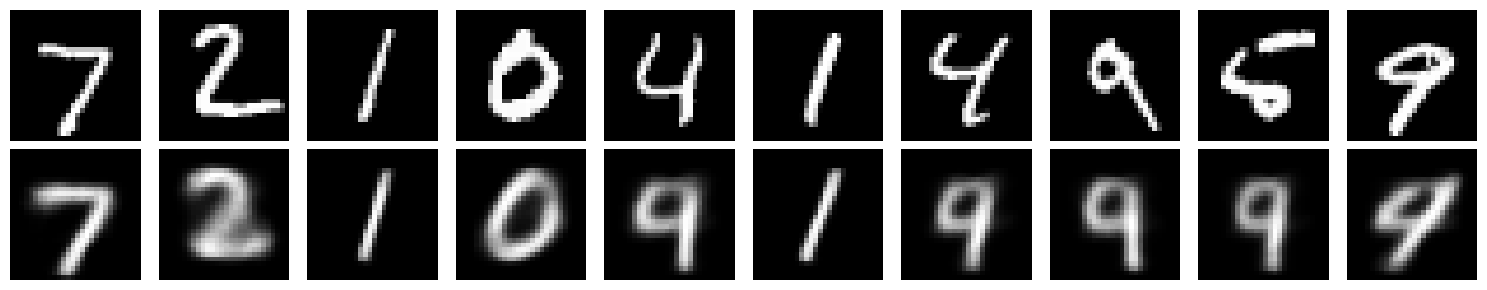

In [44]:
vae.eval()
x_test, _ = next(iter(test_loader))
x_test = x_test[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x_test)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(x_test[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Originale")
axes[1, 0].set_ylabel("VAE")
plt.tight_layout()
plt.show()

### Etape 5 - Visualiser l'espace latent

On affiche `mu`, le centre de la distribution latente de chaque image. Les labels servent seulement a colorer le graphique, pas a entrainer le VAE.

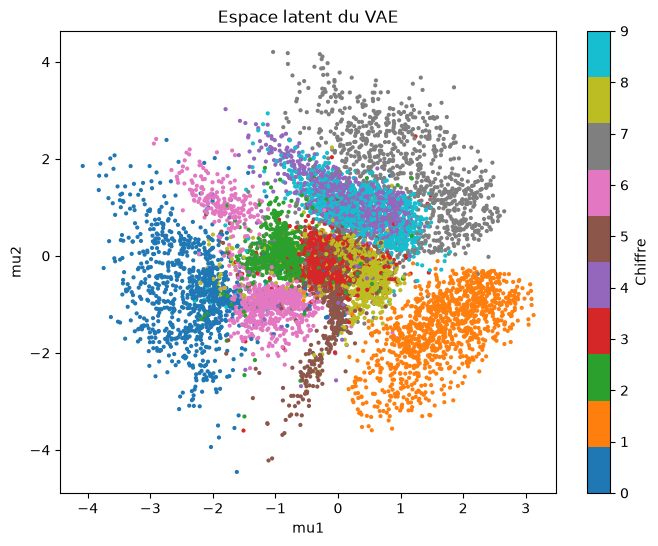

In [45]:
vae.eval()
means, labels_latent = [], []
with torch.no_grad():
    for x, y in test_loader:
        mu, _ = vae.encode(x.to(device))
        means.append(mu.cpu())
        labels_latent.append(y)

means = torch.cat(means).numpy()
labels_latent = torch.cat(labels_latent).numpy()
plt.figure(figsize=(8, 6))
scatter = plt.scatter(means[:, 0], means[:, 1], c=labels_latent, s=4, cmap="tab10")
plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter, label="Chiffre")
plt.show()

### Etape 6 - Generer de nouvelles images

Le VAE permet de generer sans image d'entree : on tire `z` dans `N(0, I)`, puis le decodeur transforme `z` en nouvelle image.

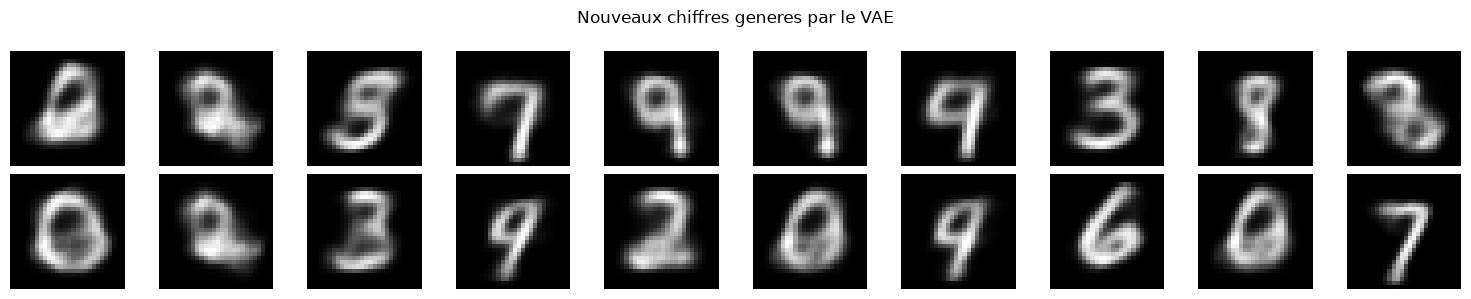

In [46]:
vae.eval()
with torch.no_grad():
    z = torch.randn(20, 2, device=device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for sample, ax in zip(samples, axes.flat):
    ax.imshow(sample.squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("Nouveaux chiffres generes par le VAE")
plt.tight_layout()
plt.show()

## Questions et reponses rapides

**1. Que produisent `mu` et `logvar` ?**  
`mu` donne le centre de la distribution latente et `logvar` controle sa dispersion.

**2. Pourquoi utiliser la reparametrisation ?**  
Elle conserve l'aleatoire de l'echantillonnage tout en permettant a l'erreur de remonter jusqu'a l'encodeur.

**3. A quoi sert la perte KL ?**  
Elle regularise l'espace latent pour le rapprocher d'une loi normale standard, ce qui rend les tirages aleatoires utiles.

**4. Que se passe-t-il si `beta` augmente ?**  
La regularisation devient plus forte : l'espace latent est plus regulier, mais les reconstructions peuvent devenir moins precises.

**5. Quelle est la difference avec l'autoencodeur classique ?**  
L'autoencodeur classique compresse vers un point fixe ; le VAE apprend une distribution et peut generer en echantillonnant `z`.

**6. Pourquoi les labels ne sont-ils pas necessaires ?**  
Le VAE apprend a reconstruire `x` et a organiser son espace latent. Les labels servent uniquement a colorer les graphiques.

In [47]:
# Partie IV : GAN sur MNIST

# Partie IV - Generative Adversarial Network (GAN)

Un GAN contient deux reseaux qui s'opposent : le generateur fabrique de fausses images et le discriminateur essaie de reconnaitre les vraies images. Cette competition pousse le generateur a produire des chiffres de plus en plus realistes.

### Etape 1 - Preparer les donnees

Le generateur utilise `Tanh`, qui produit des valeurs entre -1 et 1. Les images MNIST sont donc normalisees dans le meme intervalle.

In [48]:
gan_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

gan_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=gan_transform,
)
gan_loader = DataLoader(gan_dataset, batch_size=128, shuffle=True)

latent_dim = 100
image_dim = 28 * 28


### Etape 2 - Construire le generateur et le discriminateur

Le generateur transforme un bruit de 100 valeurs en image. Le discriminateur recoit une image aplatie et renvoie un score : plus le score est eleve, plus il pense que l'image est reelle.

In [49]:
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, image_dim),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.network(noise)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(image_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )

    def forward(self, images):
        return self.network(images)


generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)
print(generator)
print(discriminator)

Generator(
  (network): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Tanh()
  )
)
Discriminator(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)


### Etape 3 - Definir les pertes et optimiseurs

`BCEWithLogitsLoss` compare le score du discriminateur a la verite : 1 pour une image reelle et 0 pour une image generee. Le generateur, lui, cherche a faire classer ses images comme reelles.

In [50]:
gan_criterion = nn.BCEWithLogitsLoss()
gan_optimizer_g = torch.optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
gan_optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

### Etape 4 - Entrainer le GAN

On entraine d'abord le discriminateur avec des images vraies et fausses, puis le generateur. `detach()` empeche la mise a jour du generateur pendant l'etape du discriminateur.

In [51]:
def train_gan(generator, discriminator, loader, epochs=5):
    fixed_noise = torch.randn(16, latent_dim, device=device)
    for epoch in range(epochs):
        total_d, total_g = 0.0, 0.0
        for real_images, _ in loader:
            real_images = real_images.to(device).flatten(start_dim=1)
            batch_size = real_images.size(0)
            real_labels = torch.ones(batch_size, 1, device=device)
            fake_labels = torch.zeros(batch_size, 1, device=device)

            discriminator.requires_grad_(True)
            gan_optimizer_d.zero_grad(set_to_none=True)
            real_scores = discriminator(real_images)
            loss_real = gan_criterion(real_scores, real_labels)
            noise = torch.randn(batch_size, latent_dim, device=device)
            fake_images = generator(noise)
            fake_scores = discriminator(fake_images.detach())
            loss_fake = gan_criterion(fake_scores, fake_labels)
            loss_d = (loss_real + loss_fake) / 2
            loss_d.backward()
            gan_optimizer_d.step()

            discriminator.requires_grad_(False)
            gan_optimizer_g.zero_grad(set_to_none=True)
            loss_g = gan_criterion(discriminator(fake_images), real_labels)
            loss_g.backward()
            gan_optimizer_g.step()
            total_d += loss_d.item()
            total_g += loss_g.item()

        print(f"Epoch {epoch + 1}/{epochs} | Loss D = {total_d / len(loader):.4f} | Loss G = {total_g / len(loader):.4f}")

        generator.eval()
        with torch.no_grad():
            preview = ((generator(fixed_noise).view(-1, 1, 28, 28) + 1) / 2).cpu()
        print("Valeurs des images generees :", float(preview.min()), "->", float(preview.max()))


train_gan(generator, discriminator, gan_loader, epochs=5)

Epoch 1/5 | Loss D = 0.4405 | Loss G = 1.4347
Valeurs des images generees : 0.0006608664989471436 -> 0.9917313456535339
Epoch 2/5 | Loss D = 0.3747 | Loss G = 2.0447
Valeurs des images generees : 9.864568710327148e-06 -> 0.9997158646583557
Epoch 3/5 | Loss D = 0.3298 | Loss G = 2.4342
Valeurs des images generees : 2.03549861907959e-05 -> 0.9998855590820312
Epoch 4/5 | Loss D = 0.3077 | Loss G = 2.5627
Valeurs des images generees : 5.960464477539063e-08 -> 0.9999623894691467
Epoch 5/5 | Loss D = 0.3135 | Loss G = 2.4365
Valeurs des images generees : 5.960464477539063e-08 -> 0.9999967813491821


### Etape 5 - Generer de nouvelles images

Apres l'entrainement, le discriminateur n'est plus necessaire. On donne simplement un nouveau bruit au generateur pour obtenir des chiffres.

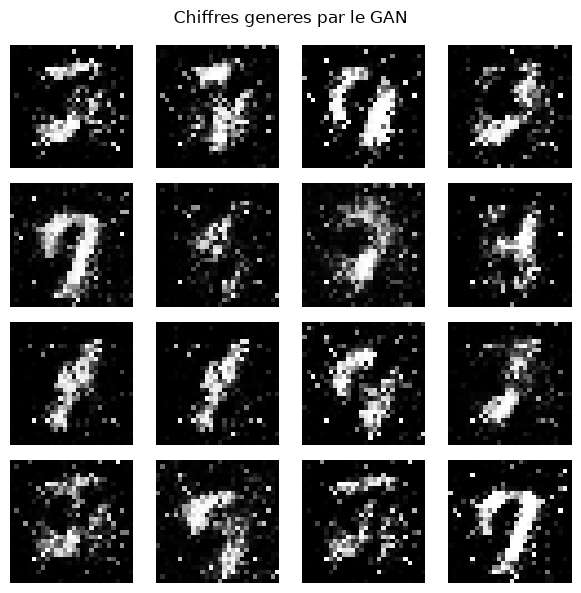

In [52]:
generator.eval()
with torch.no_grad():
    generated = generator(torch.randn(16, latent_dim, device=device))
    generated = ((generated.view(-1, 1, 28, 28) + 1) / 2).clamp(0, 1).cpu()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, image in zip(axes.flat, generated):
    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Chiffres generes par le GAN")
plt.tight_layout()
plt.show()

## Questions et reponses rapides

**1. Quel est le role du generateur ?**  
Il transforme un bruit aleatoire en une image qui doit ressembler aux images MNIST.

**2. Quel est le role du discriminateur ?**  
Il apprend a distinguer une vraie image MNIST d'une image produite par le generateur.

**3. Pourquoi les deux reseaux sont-ils entraines avec des objectifs opposes ?**  
Le discriminateur veut reconnaitre les faux, tandis que le generateur veut le tromper. Cette competition ameliore les images generees.

**4. Pourquoi les labels MNIST ne sont-ils pas utilises ?**  
Ce GAN est non conditionnel : il apprend la distribution generale des chiffres, sans recevoir la classe de chaque image.

**5. Qu'est-ce que le mode collapse ?**  
C'est un probleme ou le generateur produit des images tres similaires et perd la diversite, meme avec des bruits differents.

**6. Peut-on demander au GAN de generer precisement un chiffre 7 ?**  
Pas avec ce GAN classique. Il faudrait ajouter les labels et construire un GAN conditionnel.

**7. Pourquoi les pertes ne diminuent-elles pas toujours regulierement ?**  
Les deux reseaux progressent en meme temps et leurs objectifs sont opposes. Il faut donc aussi observer la qualite et la diversite des images.

# Partie V - Modeles de diffusion

Un modele de diffusion apprend a retirer progressivement le bruit. Pendant l'apprentissage, on ajoute un bruit connu a une image ; le reseau apprend ensuite a predire ce bruit pour pouvoir generer une image a partir de bruit pur.

### Etape 1 - Preparer les donnees

Les images sont placees entre -1 et 1. Cette echelle correspond a la sortie du modele de diffusion.

In [ ]:
diffusion_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
diffusion_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=diffusion_transform
)
diffusion_loader = DataLoader(diffusion_dataset, batch_size=128, shuffle=True)
T = 100
image_channels = 1


### Etape 2 - Ajouter du bruit

A l'instant `t`, on melange l'image originale `x0` avec un bruit gaussien. Plus `t` est grand, plus l'image devient difficile a reconnaitre.

In [ ]:
betas = torch.linspace(1e-4, 0.02, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

def extract(values, t, shape):
    result = values.gather(0, t)
    return result.view(t.shape[0], *((1,) * (len(shape) - 1)))

def add_noise(x0, t):
    noise = torch.randn_like(x0)
    alpha_bar = extract(alpha_bars, t, x0.shape)
    xt = torch.sqrt(alpha_bar) * x0 + torch.sqrt(1 - alpha_bar) * noise
    return xt, noise

### Etape 3 - Observer la degradation

Cette grille montre la meme image a plusieurs temps. Au debut le chiffre est visible ; a la fin il est presque remplace par du bruit.

In [ ]:
x0, _ = diffusion_dataset[0]
x0 = x0.unsqueeze(0).to(device)
times = torch.tensor([0, 20, 40, 60, 80, 99], device=device)
noise = torch.randn_like(x0)
fig, axes = plt.subplots(1, len(times), figsize=(12, 2))
for ax, time in zip(axes, times):
    alpha_bar = alpha_bars[time]
    noisy = torch.sqrt(alpha_bar) * x0 + torch.sqrt(1 - alpha_bar) * noise
    ax.imshow(noisy[0, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"t={time.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Etape 4 - Construire le reseau

Le reseau recoit une image bruitee et le temps `t`. Il renvoie un bruit predit de meme forme que l'image. L'information temporelle permet d'adapter le denoising au niveau de bruit.

In [ ]:
class DiffusionModel(nn.Module):
    def __init__(self, timesteps):
        super().__init__()
        self.time_embedding = nn.Embedding(timesteps, 28 * 28)
        self.network = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 28 * 28),
        )

    def forward(self, x, t):
        flat = x.flatten(start_dim=1)
        hidden = flat + self.time_embedding(t)
        return self.network(hidden).view(-1, 1, 28, 28)


diffusion_model = DiffusionModel(T).to(device)
print(diffusion_model)

### Etape 5 - Apprendre a predire le bruit

Pour chaque image, on choisit un temps aleatoire, on ajoute un bruit connu, puis on compare le bruit predit au bruit reel avec `MSELoss`. Les labels MNIST ne sont pas utilises.

In [ ]:
diffusion_optimizer = torch.optim.Adam(diffusion_model.parameters(), lr=2e-4)
diffusion_history = []

def train_diffusion(model, loader, epochs=3):
    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        for x, _ in loader:
            x = x.to(device)
            t = torch.randint(0, T, (x.size(0),), device=device)
            noisy, true_noise = add_noise(x, t)
            predicted_noise = model(noisy, t)
            loss = F.mse_loss(predicted_noise, true_noise)
            diffusion_optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            diffusion_optimizer.step()
            total_loss += loss.item()
        mean_loss = total_loss / len(loader)
        diffusion_history.append(mean_loss)
        print(f"Epoch {epoch + 1}/{epochs} - MSE bruit = {mean_loss:.4f}")

train_diffusion(diffusion_model, diffusion_loader, epochs=3)

### Etape 6 - Generation par diffusion inverse

On commence avec du bruit pur, puis on retire progressivement le bruit de `T-1` jusqu'a `0`. Le modele predit le bruit present a chaque etape.

In [ ]:
@torch.no_grad()
def generate_diffusion_images(model, n_samples=16):
    model.eval()
    x = torch.randn(n_samples, 1, 28, 28, device=device)
    for step in reversed(range(T)):
        t = torch.full((n_samples,), step, device=device, dtype=torch.long)
        predicted_noise = model(x, t)
        alpha = alphas[step]
        alpha_bar = alpha_bars[step]
        x = (x - (1 - alpha) / torch.sqrt(1 - alpha_bar) * predicted_noise) / torch.sqrt(alpha)
        if step > 0:
            x = x + torch.sqrt(betas[step]) * torch.randn_like(x)
    return ((x.clamp(-1, 1) + 1) / 2).cpu()

diffusion_samples = generate_diffusion_images(diffusion_model)
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, image in zip(axes.flat, diffusion_samples):
    ax.imshow(image[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Chiffres generes par diffusion")
plt.tight_layout()
plt.show()

## Questions et reponses rapides

**1. Quelle est la diffusion directe ?**  
C'est l'ajout progressif de bruit a une image reelle jusqu'a obtenir presque du bruit pur.

**2. Quelle est la diffusion inverse ?**  
C'est le processus appris qui retire progressivement le bruit pour reconstruire une image.

**3. Que predit le reseau ?**  
Il predit le bruit ajoute, et non directement le chiffre ou son label.

**4. Pourquoi donner le temps `t` au reseau ?**  
Le reseau doit savoir si l'image est legerement ou fortement bruitee pour appliquer le bon denoising.

**5. Pourquoi utiliser `MSELoss` ?**  
Elle mesure l'ecart entre le bruit reel et le bruit predit, valeur par valeur.

**6. Pourquoi les labels ne sont-ils pas necessaires ?**  
Le modele apprend uniquement a retirer le bruit. Les labels ne sont donc pas necessaires dans cette version non conditionnelle.

**7. Quelle est la difference avec un GAN ?**  
Le GAN apprend avec un generateur et un discriminateur en competition. La diffusion apprend a denoiser et genere une image par une suite d'etapes inverses.
